In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [3]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Dense, Embedding 
from tensorflow.keras.layers import Conv1D, GlobalMaxPooling1D                 # <<<<============ Changes here
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.util import ngrams
import matplotlib.pyplot as plt


In [4]:
sentences = [ 
    "the cat is walking in the bedroom",
    "a dog was running in a room",
    "the cat is running in a room",
    "a dog is walking in a bedroom",
    "the dog was walking in the room"
]

In [5]:
# Data preprocessing
tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)
word2idx = tokenizer.word_index
idx2word = { v:k for (k,v) in word2idx.items()}
sequences = tokenizer.texts_to_sequences(sentences)

In [6]:
print(word2idx)
print(idx2word)
print(sequences)

{'the': 1, 'in': 2, 'a': 3, 'is': 4, 'walking': 5, 'dog': 6, 'room': 7, 'cat': 8, 'bedroom': 9, 'was': 10, 'running': 11}
{1: 'the', 2: 'in', 3: 'a', 4: 'is', 5: 'walking', 6: 'dog', 7: 'room', 8: 'cat', 9: 'bedroom', 10: 'was', 11: 'running'}
[[1, 8, 4, 5, 2, 1, 9], [3, 6, 10, 11, 2, 3, 7], [1, 8, 4, 11, 2, 3, 7], [3, 6, 4, 5, 2, 3, 9], [1, 6, 10, 5, 2, 1, 7]]


In [10]:
n=4 #4 n-grams
list_ngrams = [list(ngrams(s, n)) for s in sequences]
array_ngrams = np.array(list_ngrams).reshape(-1,n)

print(list_ngrams)
print(array_ngrams)

[[(1, 8, 4, 5), (8, 4, 5, 2), (4, 5, 2, 1), (5, 2, 1, 9)], [(3, 6, 10, 11), (6, 10, 11, 2), (10, 11, 2, 3), (11, 2, 3, 7)], [(1, 8, 4, 11), (8, 4, 11, 2), (4, 11, 2, 3), (11, 2, 3, 7)], [(3, 6, 4, 5), (6, 4, 5, 2), (4, 5, 2, 3), (5, 2, 3, 9)], [(1, 6, 10, 5), (6, 10, 5, 2), (10, 5, 2, 1), (5, 2, 1, 7)]]
[[ 1  8  4  5]
 [ 8  4  5  2]
 [ 4  5  2  1]
 [ 5  2  1  9]
 [ 3  6 10 11]
 [ 6 10 11  2]
 [10 11  2  3]
 [11  2  3  7]
 [ 1  8  4 11]
 [ 8  4 11  2]
 [ 4 11  2  3]
 [11  2  3  7]
 [ 3  6  4  5]
 [ 6  4  5  2]
 [ 4  5  2  3]
 [ 5  2  3  9]
 [ 1  6 10  5]
 [ 6 10  5  2]
 [10  5  2  1]
 [ 5  2  1  7]]


In [11]:
# training data
x_train = array_ngrams[:, :-1]
y_train = array_ngrams[:, -1]

In [12]:
m = 8                   # word embedding size vector
V = len(word2idx) + 1   # vocabulary size
n_filters = 10          # no. of filters in Conv1D
filter_size  = 2        # size of convolution window

In [13]:
# create NPLM model
x_input = Input(batch_shape = (None, x_train.shape[1]))
x_embed = Embedding(input_dim=V, output_dim=m, name='emb')(x_input)   

# change LSTMs here
# x_lstm = LSTM(r)(x_embed)


# into cnn layers
x_conv = Conv1D(n_filters, filter_size, padding='same')(x_embed)
x_pool = GlobalMaxPooling1D()(x_conv)
y_output = Dense(V, activation='softmax')(x_pool)           #change final layer from x_lstm to x_pool max pooled layer

# ============comment out below============
# x_concat = Flatten()(x_embed)
# Hx = Dense(h, activation='tanh')(x_concat)
# Wx = Dense(V, use_bias = False)(x_concat)
# Ux = Dense(V)(Hx)
# y = Add()([Wx, Ux])
# y_prob = Activation('softmax')(y)

E0000 00:00:1791873410.002122   34668 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [14]:
model = Model(x_input, y_output)
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.01)
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emb (Embedding)                 │ (None, 3, 8)           │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 3, 10)          │           170 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 10)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 398 (1.55 KB)

 Trainable params: 398 (1.55 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# fit data to the model
hist = model.fit(x_train, y_train, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 855ms/step - loss: 2.4888
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 2.4536
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 2.4204
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 2.3841
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 2.3435
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 2.2986
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 2.2482
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 2.1923
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 2.1311
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 2.0648
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.9934
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 1.9175
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.8374
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 1.7537
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 1.6670
Epoch 16/100
1/1 ━

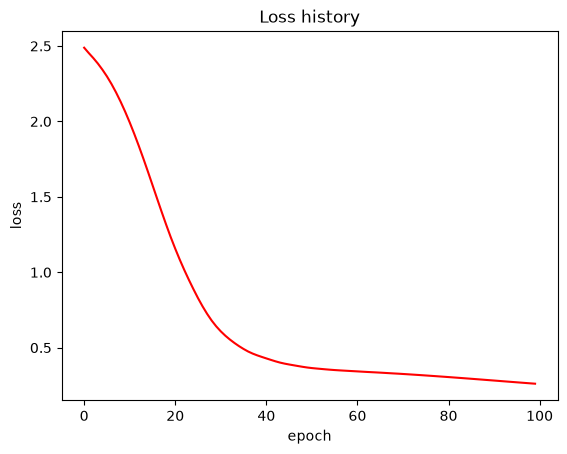

In [16]:
# losss history
plt.plot(hist.history['loss'], color='red')
plt.title("Loss history")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [17]:
# matrix C
C = model.get_layer('emb').get_weights()[0]

In [18]:
# word vector
print("\nWord vectors:")
for word, idx in word2idx.items():
    word_vector = C[idx, :]
    print("{:10s}".format(word), end='')
    print(word_vector.round(3))


Word vectors:
the       [-0.68  -0.744 -0.223  0.6    0.462 -0.428  0.843 -0.496]
in        [-0.712  1.013 -0.327 -0.648  0.708 -0.507 -0.976  0.61 ]
a         [-0.862 -0.017 -0.237  0.002  0.982 -0.362  0.476  0.045]
is        [ 0.665 -0.326  0.308  0.813 -0.445  0.775 -0.134 -0.723]
walking   [ 0.897 -0.337 -0.1    0.602 -1.147  0.05   0.197 -0.477]
dog       [-0.331  0.847  0.862  0.209 -0.547 -0.084 -0.756  0.193]
room      [ 0.036 -0.009 -0.04   0.015  0.04   0.014 -0.02  -0.034]
cat       [-0.119  0.409  0.614  0.458 -0.603  0.206 -0.429 -0.273]
bedroom   [-0.045  0.043  0.044  0.035  0.005 -0.012 -0.008 -0.008]
was       [-0.036 -0.766  0.434  0.831  0.011  0.427 -0.239 -0.371]
running   [ 0.32   0.441  0.616 -0.037 -0.445  0.659  0.255  0.403]


In [19]:
# P(w4 | w1, w2, w3)
print("\nP(w4 | w1, w2, w3):")
x = x_train[0] #"the", "cat", "is"
p = model.predict(
    x.reshape(1, -1),
    verbose=0
)[0]

print(idx2word[x[0]],idx2word[x[1]],idx2word[x[2]], ':')

for word, idx in word2idx.items():
    print("{:10s}: {:.3f}".format(word, p[idx]))


P(w4 | w1, w2, w3):
the cat is :
the       : 0.000
in        : 0.007
a         : 0.000
is        : 0.000
walking   : 0.558
dog       : 0.000
room      : 0.000
cat       : 0.000
bedroom   : 0.000
was       : 0.000
running   : 0.436


In [20]:
# sentence matrix
print("\n sentence matrix:")
i=0
print('sen:', sentences[i], ':')
print(C[sequences[i]].round(2))


 sentence matrix:
sen: the cat is walking in the bedroom :
[[-0.68 -0.74 -0.22  0.6   0.46 -0.43  0.84 -0.5 ]
 [-0.12  0.41  0.61  0.46 -0.6   0.21 -0.43 -0.27]
 [ 0.66 -0.33  0.31  0.81 -0.45  0.77 -0.13 -0.72]
 [ 0.9  -0.34 -0.1   0.6  -1.15  0.05  0.2  -0.48]
 [-0.71  1.01 -0.33 -0.65  0.71 -0.51 -0.98  0.61]
 [-0.68 -0.74 -0.22  0.6   0.46 -0.43  0.84 -0.5 ]
 [-0.04  0.04  0.04  0.04  0.01 -0.01 -0.01 -0.01]]
